# HandSpell - Sign Language MNIST

## 1. Load and Preprocess the dataset

In [3]:
## 0. Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay, precision_score, recall_score, f1_score, roc_auc_score

In [4]:
## 1.Load the Sign Language MNIST dataset
# Load the dataset
train_df = pd.read_csv("../data/sign_mnist_train.csv")

print("Dataset shape: ", train_df.shape)
display(train_df.head())

y = train_df['label'].values
X = train_df.drop(columns=['label']).values

X = X.reshape(-1, 28, 28, 1)
X = X.astype('float32') / 255.0

Dataset shape:  (27455, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [5]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

## 2. Train a small CNN baseline

In [6]:
model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dense(128),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Dropout(0.4),

        layers.Dense(26, activation='softmax')
    ])

E0000 00:00:1791974891.261029   25948 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [7]:
model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 26)             │         3,354 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,602 (1.62 MB)

 Trainable params: 424,154 (1.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [8]:
early_stop = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    )

history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=15,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 51s 99ms/step - accuracy: 0.9114 - loss: 0.4264 - val_accuracy: 0.6176 - val_loss: 1.3741
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 35s 102ms/step - accuracy: 0.9998 - loss: 0.0209 - val_accuracy: 1.0000 - val_loss: 0.0101
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 35s 103ms/step - accuracy: 0.9999 - loss: 0.0083 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 50s 129ms/step - accuracy: 0.9999 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 35s 103ms/step - accuracy: 0.9998 - loss: 0.0044 - val_accuracy: 0.9987 - val_loss: 0.0131
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 37s 108ms/step - accuracy: 1.0000 - loss: 0.0032 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


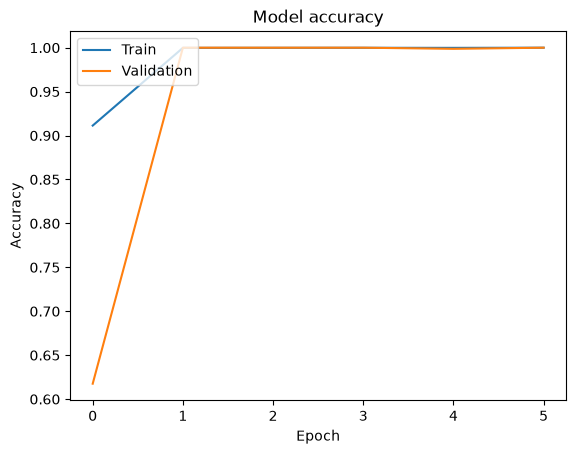

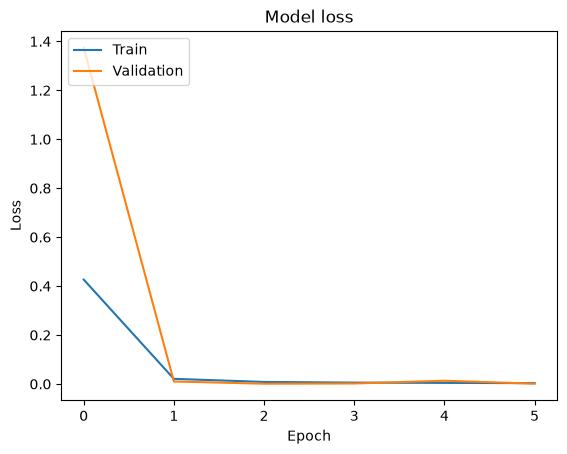

In [9]:
# Plot training & validation accuracy values
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Plot training & validation loss values
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [10]:
model_filename = "kazim_handspell_mnist_custom_cnn.keras"
model.save("../models/" + model_filename)

In [11]:
test_df = pd.read_csv("../raw_data/sign_mnist_test.csv")

print("Dataset shape: ", test_df.shape)
display(test_df.head())

y_test = test_df['label'].values

X_test = test_df.drop(columns=['label']).values
X_test = X_test.reshape(-1, 28, 28, 1)
X_test = X_test.astype('float32') / 255.0

Dataset shape:  (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,10,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


In [12]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=64, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:" , test_accuracy)

Test loss: 0.22756223380565643
Test accuracy: 0.9397657513618469


In [13]:
y_scores= model.predict(X_test, verbose=1)
print(y_scores)
y_pred = np.argmax(y_scores, axis=1)

labels = np.sort(np.unique(y_test))
label_names = [chr(int(label) + ord('A')) for label in labels]

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step
[[1.07503274e-06 1.22027104e-05 3.84411513e-04 ... 3.52939569e-05
  1.93293690e-05 8.13932616e-07]
 [4.13875416e-04 2.59378878e-03 6.27379122e-05 ... 7.84489093e-04
  5.01396891e-04 5.08077028e-06]
 [2.88137289e-06 4.12674490e-05 3.84874465e-06 ... 5.06696460e-06
  1.56386915e-04 2.13552198e-06]
 ...
 [2.09716927e-05 7.41416898e-06 9.97736573e-01 ... 7.34462155e-05
  8.81129308e-05 7.39417601e-07]
 [6.79010145e-06 2.51074493e-06 1.58452065e-06 ... 2.83125632e-06
  1.23546595e-08 2.90243696e-09]
 [7.37117807e-06 2.79823212e-06 9.99398470e-01 ... 2.98059640e-05
  5.64606780e-05 3.63503347e-07]]


In [14]:
print(classification_report(y_test, y_pred, labels=labels, target_names=label_names, digits=3, zero_division=0))

              precision    recall  f1-score   support

           A      0.917     1.000     0.957       331
           B      1.000     1.000     1.000       432
           C      1.000     1.000     1.000       310
           D      1.000     1.000     1.000       245
           E      0.959     0.992     0.975       498
           F      0.976     1.000     0.988       247
           G      0.852     0.991     0.916       348
           H      0.993     0.927     0.958       436
           I      1.000     0.906     0.951       288
           K      0.914     0.937     0.925       331
           L      0.963     1.000     0.981       209
           M      0.974     0.944     0.959       394
           N      0.912     0.753     0.825       291
           O      1.000     0.919     0.958       246
           P      1.000     1.000     1.000       347
           Q      1.000     1.000     1.000       164
           R      0.730     0.806     0.766       144
           S      0.980    

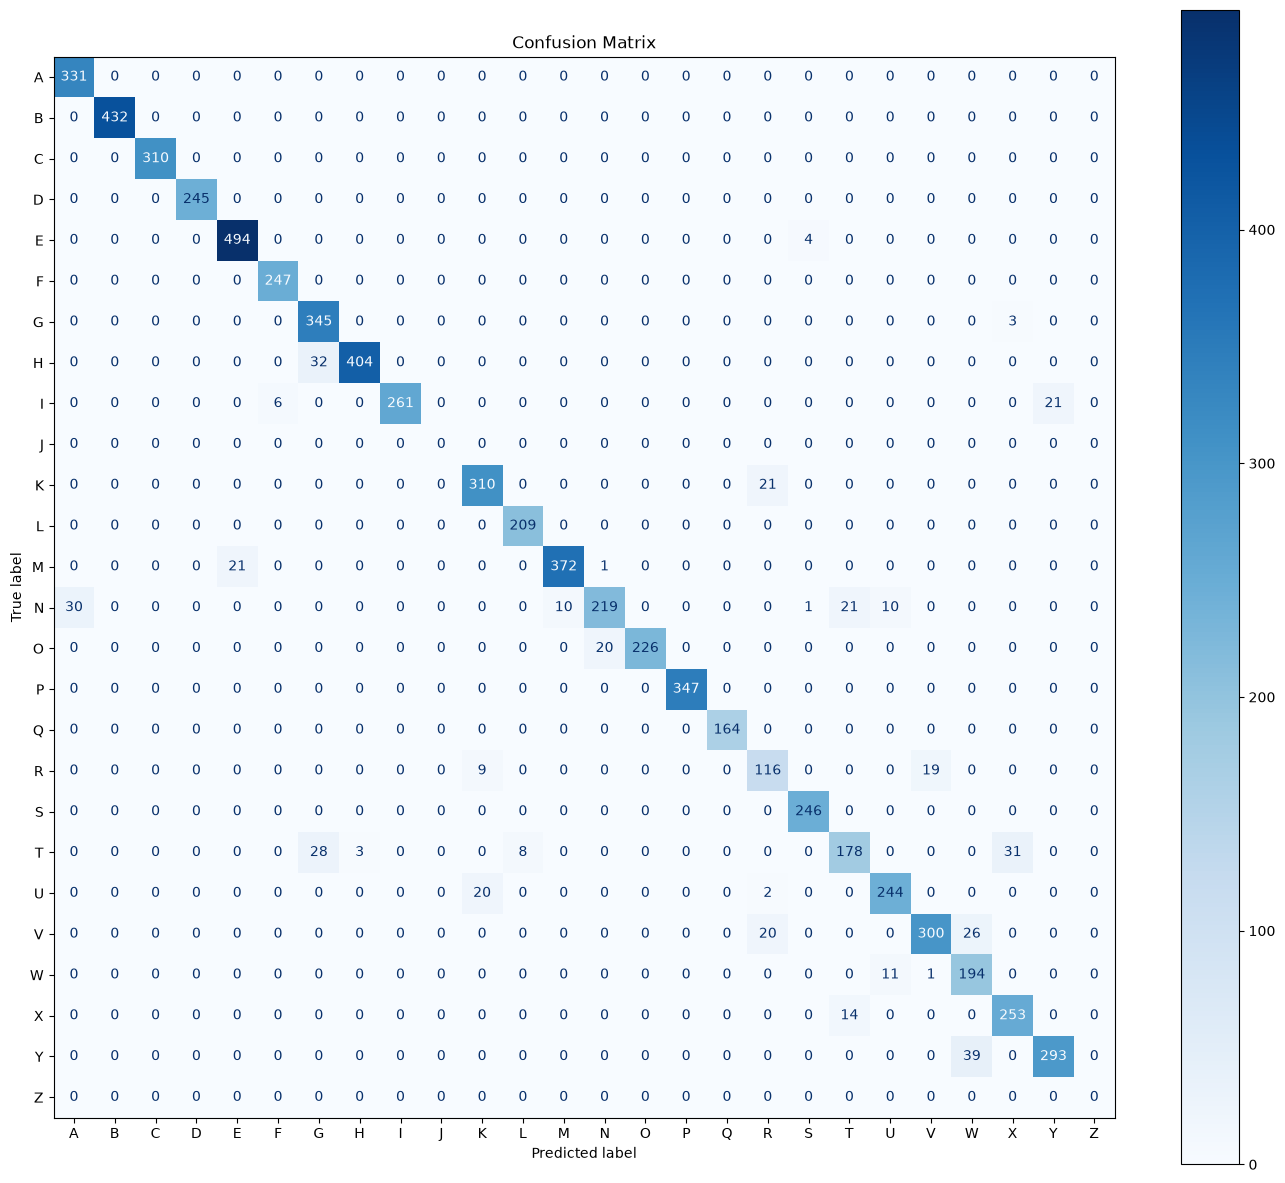

In [15]:
all_labels = np.arange(26)
all_letters = [chr(i + ord('A')) for i in all_labels]

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=all_labels, display_labels=all_letters, cmap='Blues', values_format='d', ax=ax
    )

ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

In [16]:
print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.2%}")

macro_f1_with_labels = f1_score(y_test, y_pred, labels=labels, average='macro', zero_division=0)
print(f"Macro F1 Score: {macro_f1_with_labels:.3f}")

Test Accuracy: 93.98%
Macro F1 Score: 0.933
